# 인공신경망(ANN)과 콘크리트 강도 공식을 결합한 목표 강도 달성 확률 예측 시스템

**입력**: 재료 7종 단위량(kg/m³), 목표 강도(MPa), 재령(기본 28일)
**출력**: 그 재령에서 압축강도가 **목표 강도 이상일 확률**(0~100%), 예상 강도 μ ± σ, 공식 예측 강도, W/B, 판정

- 데이터: UCI *Concrete Compressive Strength* (I-Cheng Yeh), CC BY 4.0, DOI 10.24432/C5PK67 — **1,030건 전부 사용**
- 공식: Abrams 법칙(물-결합재비) + ACI 209 재령 계수를 ANN 입력에 추가
- 확률: A(회귀 + 오차 분포)와 B(직접 분류 + 보정)를 모두 만들고 테스트 성능으로 선택

**실행**: 런타임 → 모두 실행. `FAST_MODE = True`면 무료 Colab에서 몇 분 안에 끝납니다.
마지막 칸에서 HTML 모델용 `model_export.json`을 만듭니다.

## 0. 설정

In [1]:
DATA_SOURCE = "auto"      # "auto": UCI에서 자동 다운로드 / "upload": 파일 직접 올리기
LOCAL_PATH = ""           # (선택) 파일 경로. 예: "/content/drive/MyDrive/Concrete_Data.xls"
UCI_ZIP_URL = "https://archive.ics.uci.edu/static/public/165/concrete+compressive+strength.zip"
RANDOM_STATE = 42
TEST_SIZE = 0.30
FAST_MODE = True          # True: 축소 탐색(빠름) / False: 전체 탐색(오래 걸림)
EVAL_TARGETS = [21, 24, 27, 30, 35, 40]   # 목표 강도별 성능을 따로 볼 값 (예측할 때 목표 강도 제한은 없음)

## 라이브러리

In [2]:
import io, json, zipfile, warnings, subprocess, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.stats import norm
from scipy.special import logit, expit
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV, cross_val_predict
from sklearn.preprocessing import MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPRegressor, MLPClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (r2_score, mean_absolute_error, mean_squared_error, brier_score_loss, log_loss,
                             roc_auc_score)
from sklearn.calibration import calibration_curve
from sklearn.exceptions import ConvergenceWarning
import joblib
warnings.filterwarnings("ignore", category=ConvergenceWarning)

def pip_install(pkg):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)

try:
    import xlrd  # noqa: F401
except ImportError:
    pip_install("xlrd")
try:
    import koreanize_matplotlib  # noqa: F401
except ImportError:
    pip_install("koreanize-matplotlib")
    try:
        import koreanize_matplotlib  # noqa: F401
    except ImportError:
        print("한글 글꼴 설치 실패: 그래프의 한글이 깨질 수 있습니다.")
plt.rcParams["axes.unicode_minus"] = False

try:
    from google.colab import files as colab_files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
print("Colab 환경:", IN_COLAB)

Colab 환경: False


## 1. 데이터 불러오기

In [3]:
NAMES = ["시멘트", "고로슬래그", "플라이애시", "물", "고성능감수제", "굵은골재", "잔골재", "재령", "압축강도"]
MATERIALS = NAMES[:7]


def read_table(name, data):
    if str(name).lower().endswith((".xls", ".xlsx")):
        return pd.read_excel(io.BytesIO(data) if isinstance(data, bytes) else data)
    return pd.read_csv(io.BytesIO(data) if isinstance(data, bytes) else data)


def load_raw():
    if LOCAL_PATH:
        print("파일 읽기:", LOCAL_PATH)
        return read_table(LOCAL_PATH, LOCAL_PATH)
    if DATA_SOURCE == "auto":
        try:
            import urllib.request
            with urllib.request.urlopen(UCI_ZIP_URL, timeout=60) as r:
                z = zipfile.ZipFile(io.BytesIO(r.read()))
            name = next(n for n in z.namelist() if n.lower().endswith(".xls"))
            print("UCI에서 내려받음:", name)
            return read_table(name, z.read(name))
        except Exception as e:
            print("자동 다운로드 실패 → 직접 올려 주세요:", e)
    print("Concrete_Data.xls (또는 같은 9개 열의 CSV)를 올려 주세요.")
    if IN_COLAB:
        up = colab_files.upload()
        name = next(iter(up))
        return read_table(name, up[name])
    path = input("파일 경로: ").strip()
    return read_table(path, path)


raw = load_raw()
assert raw.shape[1] == 9, f"열이 9개여야 합니다 (현재 {raw.shape[1]}개)"
raw.columns = NAMES
print(raw.shape)

파일 읽기: /home/user/concrete_strength/data_build/raw/Concrete_Data.xls
(1030, 9)


## 2. 데이터 점검 (1,030건 전부 사용)

- 결측값, 물리적으로 불가능한 값을 확인합니다. 있으면 그 행만 뺍니다.
- **완전히 같은 행**과 **배합·재령이 같고 강도만 다른 행**은 확인해서 건수만 기록하고, **지우거나 평균 내지 않고 그대로 씁니다.**
  (같은 조건의 반복 시험은 강도가 얼마나 흩어지는지 보여 주는 정보이기도 합니다)
- 재료 7종이 같으면 같은 배합 → **배합번호**. 같은 배합(과 그 중복 행)은 항상 학습·테스트 한쪽에만 들어갑니다.

In [4]:
df = raw.copy()
n_na = int(df.isna().any(axis=1).sum())
bad = (df[NAMES] < 0).any(axis=1) | (df["시멘트"] <= 0) | (df["물"] <= 0) | (df["재령"] <= 0) | (df["압축강도"] <= 0)
n_dup = int(df.duplicated().sum())
same_cond = df.duplicated(subset=NAMES[:8], keep=False) & ~df.duplicated(keep=False)
n_rep_rows = int((df.duplicated(subset=NAMES[:8], keep=False)).sum())
df = df[~(df.isna().any(axis=1) | bad)].reset_index(drop=True)
df["배합번호"] = df.groupby(MATERIALS).ngroup() + 1
check = pd.DataFrame([
    ("원자료", 1030 if len(raw) == 1030 else len(raw), "-"),
    ("결측값이 있는 행", n_na, "있으면 제외"),
    ("물리적으로 불가능한 값", int(bad.sum()), "있으면 제외"),
    ("완전히 같은 행 (두 번째 이후)", n_dup, "그대로 사용"),
    ("배합·재령이 같은 행 (완전 중복 포함, 전체)", n_rep_rows, "그대로 사용"),
    ("최종 사용 행", len(df), "-"),
    ("서로 다른 배합", df["배합번호"].nunique(), "-"),
], columns=["항목", "건수", "처리"])
display(check)
df[NAMES].describe().round(2).T

,항목,건수,처리
0,원자료,1030,-
1,결측값이 있는 행,0,있으면 제외
2,물리적으로 불가능한 값,0,있으면 제외
3,완전히 같은 행 (두 번째 이후),25,그대로 사용
4,"배합·재령이 같은 행 (완전 중복 포함, 전체)",53,그대로 사용
5,최종 사용 행,1030,-
6,서로 다른 배합,428,-


,count,mean,std,min,25%,50%,75%,max
시멘트,1030.0,281.17,104.51,102.00,192.38,272.90,350.00,540.0
고로슬래그,1030.0,73.90,86.28,0.00,0.00,22.00,142.95,359.4
플라이애시,1030.0,54.19,64.00,0.00,0.00,0.00,118.27,200.1
물,1030.0,181.57,21.36,121.75,164.90,185.00,192.00,247.0
고성능감수제,1030.0,6.20,5.97,0.00,0.00,6.35,10.16,32.2
굵은골재,1030.0,972.92,77.75,801.00,932.00,968.00,1029.40,1145.0
잔골재,1030.0,773.58,80.18,594.00,730.95,779.51,824.00,992.6
재령,1030.0,45.66,63.17,1.00,7.00,28.00,56.00,365.0
압축강도,1030.0,35.82,16.71,2.33,23.71,34.44,46.14,82.6


## 3. 배합 기준 그룹 분할 (학습 70% / 테스트 30%)

In [5]:
gss = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=RANDOM_STATE)
tr_i, te_i = next(gss.split(df, groups=df["배합번호"]))
train, test = df.iloc[tr_i].reset_index(drop=True), df.iloc[te_i].reset_index(drop=True)
print(f"학습 {len(train)}건 / 테스트 {len(test)}건 ({len(test) / len(df):.1%}), "
      f"겹치는 배합 {len(set(train['배합번호']) & set(test['배합번호']))}개")
print(f"테스트 중 28일 {int((test['재령'] == 28).sum())}건")

학습 729건 / 테스트 301건 (29.2%), 겹치는 배합 0개
테스트 중 28일 127건


## 4. 콘크리트 강도 공식

| 값 | 식 |
|---|---|
| W/C | 물 ÷ 시멘트 |
| W/B | 물 ÷ (시멘트 + 고로슬래그 + 플라이애시) |
| Abrams 28일 강도 | A ÷ B<sup>W/B</sup> |
| ACI 209 재령 계수 | g(t) = t ÷ (4 + 0.85t) |
| 공식 예측 강도 | Abrams 28일 강도 × g(t) ÷ g(28) |

계수 A, B는 **학습용 데이터만으로** 맞춥니다(전 재령 학습 행 사용). 테스트 데이터는 쓰지 않습니다.

In [6]:
def age_factor(t):
    return t / (4.0 + 0.85 * t)


def formula_strength(wb, t, A, B):
    return A / B ** wb * age_factor(t) / age_factor(28.0)


def add_formula(d, A, B):
    d = d.copy()
    d["결합재"] = d["시멘트"] + d["고로슬래그"] + d["플라이애시"]
    d["W/C"] = d["물"] / d["시멘트"]
    d["W/B"] = d["물"] / d["결합재"]
    d["재령계수"] = age_factor(d["재령"])
    d["공식강도"] = formula_strength(d["W/B"], d["재령"], A, B)
    return d


wb_tr = train["물"] / (train["시멘트"] + train["고로슬래그"] + train["플라이애시"])
(A_FIT, B_FIT), _ = curve_fit(lambda X, A, B: formula_strength(X[0], X[1], A, B),
                              (wb_tr.values, train["재령"].values), train["압축강도"].values, p0=[100, 10], maxfev=20000)
train, test = add_formula(train, A_FIT, B_FIT), add_formula(test, A_FIT, B_FIT)
print(f"Abrams 계수 (학습용으로 맞춤): A = {A_FIT:.2f}, B = {B_FIT:.3f}")
print(f"예: W/B 0.45인 배합의 28일 공식 강도 = {formula_strength(0.45, 28, A_FIT, B_FIT):.1f} MPa")

Abrams 계수 (학습용으로 맞춤): A = 122.32, B = 11.980
예: W/B 0.45인 배합의 28일 공식 강도 = 40.0 MPa


## 5. 강도 예측 모델 비교 ①공식만 ②ANN만 ③공식 결합 ANN

| 모델 | 입력 |
|---|---|
| ① 공식만 | W/B, 재령 → 공식 예측 강도 |
| ② ANN만 | 재료 7종 + 재령 (8개) |
| ③ 공식 결합 ANN | 재료 7종 + 재령 + W/C + W/B + 재령계수 + 공식강도 (12개) |

In [7]:
F_ANN = MATERIALS + ["재령"]
F_HYB = MATERIALS + ["재령", "W/C", "W/B", "재령계수", "공식강도"]

if FAST_MODE:
    grid_r = {"mlp__hidden_layer_sizes": [(64,), (128, 64, 32)], "mlp__activation": ["relu", "tanh"],
              "mlp__alpha": [1e-4, 1e-3], "mlp__learning_rate_init": [0.01]}
else:
    grid_r = {"mlp__hidden_layer_sizes": [(32,), (64,), (64, 32), (128, 64), (128, 64, 32)],
              "mlp__activation": ["relu", "tanh"], "mlp__alpha": [1e-4, 1e-3, 1e-2],
              "mlp__learning_rate_init": [0.001, 0.01]}


def reg_pipe():
    return Pipeline([("scale", MinMaxScaler()),
                     ("mlp", MLPRegressor(max_iter=5000, early_stopping=True, validation_fraction=0.15,
                                          n_iter_no_change=50, random_state=RANDOM_STATE))])


def fit_reg(features):
    s = GridSearchCV(reg_pipe(), grid_r, cv=GroupKFold(5), scoring="neg_root_mean_squared_error", n_jobs=-1, verbose=1)
    s.fit(train[features], train["압축강도"], groups=train["배합번호"])
    print("  최적 설정:", s.best_params_, f"교차검증 RMSE {-s.best_score_:.2f}")
    return s.best_estimator_


def rscore(y, p):
    return {"R²": r2_score(y, p), "MAE(MPa)": mean_absolute_error(y, p), "RMSE(MPa)": np.sqrt(mean_squared_error(y, p))}


print("② ANN만"); reg_ann = fit_reg(F_ANN)
print("③ 공식 결합 ANN"); reg_hyb = fit_reg(F_HYB)
PRED = {"① 공식만": test["공식강도"].values, "② ANN만": reg_ann.predict(test[F_ANN]),
        "③ 공식 결합 ANN": reg_hyb.predict(test[F_HYB])}
y_te = test["압축강도"].values
comp = pd.DataFrame({k: rscore(y_te, p) for k, p in PRED.items()}).T.round(3)
display(comp)

groups_mix = {"전체": np.ones(len(test), bool),
              "시멘트만 (슬래그·플라이애시 0)": ((test["고로슬래그"] == 0) & (test["플라이애시"] == 0)).values,
              "혼화재 사용": ((test["고로슬래그"] > 0) | (test["플라이애시"] > 0)).values,
              "감수제 사용": (test["고성능감수제"] > 0).values,
              "재령 28일": (test["재령"] == 28).values}
by_kind = pd.DataFrame({k: {f"{m} RMSE": np.sqrt(mean_squared_error(y_te[g], p[g])) for m, p in PRED.items()} | {"건수": int(g.sum())}
                        for k, g in groups_mix.items()}).T.round(2)
display(by_kind)

② ANN만
Fitting 5 folds for each of 8 candidates, totalling 40 fits


  최적 설정: {'mlp__activation': 'relu', 'mlp__alpha': 0.0001, 'mlp__hidden_layer_sizes': (128, 64, 32), 'mlp__learning_rate_init': 0.01} 교차검증 RMSE 6.87
③ 공식 결합 ANN
Fitting 5 folds for each of 8 candidates, totalling 40 fits


  최적 설정: {'mlp__activation': 'tanh', 'mlp__alpha': 0.0001, 'mlp__hidden_layer_sizes': (64,), 'mlp__learning_rate_init': 0.01} 교차검증 RMSE 6.80


,R²,MAE(MPa),RMSE(MPa)
① 공식만,0.751,6.078,7.877
② ANN만,0.800,5.327,7.060
③ 공식 결합 ANN,0.859,4.654,5.925


,① 공식만 RMSE,② ANN만 RMSE,③ 공식 결합 ANN RMSE,건수
전체,7.88,7.06,5.92,301.0
시멘트만 (슬래그·플라이애시 0),5.13,8.59,5.26,55.0
혼화재 사용,8.37,6.67,6.06,246.0
감수제 사용,8.39,7.61,6.15,208.0
재령 28일,9.47,6.98,6.40,127.0


## 6. 확률 계산 방법 A: 회귀 + 오차 분포

강도 예측에는 ①②③ 중 **테스트 RMSE가 가장 작은 ANN**을 씁니다.
1. 학습용 데이터에서 **그룹 교차검증 예측값**과 실제값의 차이(오차)를 구함
2. σ 고정: 오차의 표준편차 하나
3. σ 가변: |오차|를 예측 강도와 재령계수로 회귀해서 배합마다 다른 σ (최소 2 MPa)
4. 달성 확률 = 1 − Φ((목표 − μ) ÷ σ)

In [8]:
best_name = "③ 공식 결합 ANN" if comp.loc["③ 공식 결합 ANN", "RMSE(MPa)"] <= comp.loc["② ANN만", "RMSE(MPa)"] else "② ANN만"
REG, F_REG = (reg_hyb, F_HYB) if best_name.startswith("③") else (reg_ann, F_ANN)
print("확률 계산에 쓸 강도 모델:", best_name)

oof = cross_val_predict(REG, train[F_REG], train["압축강도"], groups=train["배합번호"], cv=GroupKFold(5))
res = train["압축강도"].values - oof
SIGMA = float(np.std(res, ddof=1))
sig_lr = LinearRegression().fit(np.c_[oof, train["재령계수"]], np.abs(res))
SIG_COEF = [float(sig_lr.intercept_), float(sig_lr.coef_[0]), float(sig_lr.coef_[1])]
SIG_MIN = 2.0


def sigma_var(mu, af):
    return np.maximum(SIG_MIN, (SIG_COEF[0] + SIG_COEF[1] * mu + SIG_COEF[2] * af) * np.sqrt(np.pi / 2))


print(f"σ 고정 = {SIGMA:.2f} MPa | σ 가변 = √(π/2) × ({SIG_COEF[0]:.2f} + {SIG_COEF[1]:.3f}·μ + {SIG_COEF[2]:.2f}·재령계수)")
mu_te = REG.predict(test[F_REG])

확률 계산에 쓸 강도 모델: ③ 공식 결합 ANN


σ 고정 = 6.82 MPa | σ 가변 = √(π/2) × (3.21 + 0.138·μ + -3.54·재령계수)


## 7. 확률 계산 방법 B: 직접 분류 + 보정

- 학습 행마다 목표 강도를 여러 개 붙여 '달성 1 / 미달 0' 정답을 만듭니다 (실제 강도는 정답 계산에만 사용).
- 학습용 목표 강도는 데이터 강도 범위를 덮도록 내부적으로만 정합니다(2.5 MPa 간격). 사용자가 넣는 목표 강도에는 제한이 없습니다.
- MLPClassifier 입력: ③의 12개 + 목표 강도
- 보정: 그룹 교차검증 예측 확률로 Platt(로지스틱)과 isotonic 보정을 각각 맞춤
- 단조 감소: 목표 강도를 낮은 값부터 올려 가며 누적 최솟값을 취해, 목표가 높을수록 확률이 커지지 않게 함

In [9]:
T_TRAIN = np.arange(2.5, 85.01, 2.5)
F_CLF = F_HYB + ["목표강도"]


def expand(d, targets):
    r = d.loc[d.index.repeat(len(targets))].copy()
    r["목표강도"] = np.tile(targets, len(d))
    r["달성"] = (r["압축강도"] >= r["목표강도"]).astype(int)
    return r.reset_index(drop=True)


tr_x = expand(train, T_TRAIN)
grid_c = ({"mlp__hidden_layer_sizes": [(64, 32), (128, 64)], "mlp__activation": ["relu", "tanh"], "mlp__alpha": [1e-3]}
          if FAST_MODE else
          {"mlp__hidden_layer_sizes": [(32,), (64, 32), (128, 64), (128, 64, 32)], "mlp__activation": ["relu", "tanh"],
           "mlp__alpha": [1e-4, 1e-3, 1e-2]})
clf_pipe = Pipeline([("scale", MinMaxScaler()),
                     ("mlp", MLPClassifier(max_iter=2000, early_stopping=True, validation_fraction=0.15,
                                           n_iter_no_change=20, random_state=RANDOM_STATE))])
search_c = GridSearchCV(clf_pipe, grid_c, cv=GroupKFold(5), scoring="neg_log_loss", n_jobs=-1, verbose=1)
search_c.fit(tr_x[F_CLF], tr_x["달성"], groups=tr_x["배합번호"])
CLF = search_c.best_estimator_
print(f"학습 행 {len(tr_x):,}개 | 최적 설정: {search_c.best_params_}")

oof_p = cross_val_predict(CLF, tr_x[F_CLF], tr_x["달성"], groups=tr_x["배합번호"], cv=GroupKFold(5), method="predict_proba")[:, 1]
platt = LogisticRegression(C=1e6).fit(logit(np.clip(oof_p, 1e-6, 1 - 1e-6)).reshape(-1, 1), tr_x["달성"])
PLATT = [float(platt.coef_[0][0]), float(platt.intercept_[0])]
iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(oof_p, tr_x["달성"])
print(f"Platt 보정: p' = 1/(1+exp(-({PLATT[0]:.3f}·logit(p) + {PLATT[1]:.3f})))")

Fitting 5 folds for each of 4 candidates, totalling 20 fits


학습 행 24,786개 | 최적 설정: {'mlp__activation': 'tanh', 'mlp__alpha': 0.001, 'mlp__hidden_layer_sizes': (128, 64)}


Platt 보정: p' = 1/(1+exp(-(0.550·logit(p) + 0.158)))


## 8. 확률 평가와 방법 선택

평가용 목표 강도: 테스트 행마다 5~80 MPa(1 MPa 간격)를 모두 붙여 평가하고, 목표 강도별(21·24·27·30·35·40)로도 따로 봅니다.

| 지표 | 좋은 방향 |
|---|---|
| Brier 점수 (확률과 실제 0/1의 차이²) | 작을수록 |
| 로그손실 (틀린 답에 높은 확신을 줄수록 큰 벌점) | 작을수록 — **방법 선택 기준** |
| ECE (예측 확률과 실제 달성 비율의 차이) | 0에 가까울수록 |
| AUC (달성/미달을 확률 순서로 가르는 능력) | 1에 가까울수록 |

In [10]:
T_EVAL = np.arange(5.0, 80.01, 1.0)
Y = (y_te[:, None] >= T_EVAL[None, :]).astype(int)


def clf_raw(d, targets):
    X = d[F_HYB].loc[d.index.repeat(len(targets))].copy()
    X["목표강도"] = np.tile(targets, len(d))
    return CLF.predict_proba(X[F_CLF])[:, 1].reshape(len(d), len(targets))


def monotone(P):
    return np.minimum.accumulate(P, axis=1)


P_raw = clf_raw(test, T_EVAL)
METHODS = {
    "A1 회귀 + σ고정": 1 - norm.cdf((T_EVAL[None, :] - mu_te[:, None]) / SIGMA),
    "A2 회귀 + σ가변": 1 - norm.cdf((T_EVAL[None, :] - mu_te[:, None]) / sigma_var(mu_te, test["재령계수"].values)[:, None]),
    "B0 분류 (보정 전)": monotone(P_raw),
    "B1 분류 + Platt": monotone(expit(PLATT[0] * logit(np.clip(P_raw, 1e-6, 1 - 1e-6)) + PLATT[1])),
    "B2 분류 + isotonic": monotone(iso.predict(P_raw.ravel()).reshape(P_raw.shape)),
    "기준: 배합 무시": np.tile([(train["압축강도"] >= t).mean() for t in T_EVAL], (len(test), 1)),
}
raw_mono = float((np.diff(P_raw, axis=1) <= 1e-9).all(axis=1).mean())
print(f"보정·단조 처리 전 분류 확률이 이미 단조 감소인 행 비율: {raw_mono:.0%}")


def ece(y, p, bins=10):
    e = np.linspace(0, 1, bins + 1); idx = np.clip(np.digitize(p, e[1:-1]), 0, bins - 1)
    return sum(abs(p[idx == k].mean() - y[idx == k].mean()) * (idx == k).mean() for k in range(bins) if (idx == k).any())


def pscore(y, p):
    p = np.clip(p, 1e-4, 1 - 1e-4)
    return {"Brier": brier_score_loss(y, p), "로그손실": log_loss(y, p, labels=[0, 1]), "ECE": ece(y, p),
            "AUC": roc_auc_score(y, p) if 0 < y.mean() < 1 else np.nan}


m28 = (test["재령"] == 28).values
prob_all = pd.DataFrame({k: pscore(Y.ravel(), P.ravel()) for k, P in METHODS.items()}).T.round(4)
prob_28 = pd.DataFrame({k: pscore(Y[m28].ravel(), P[m28].ravel()) for k, P in METHODS.items()}).T.round(4)
print("전체 테스트 (모든 재령)"); display(prob_all)
print("재령 28일 테스트만"); display(prob_28)

cands = [k for k in METHODS if not k.startswith("기준")]
CHOSEN = min(cands, key=lambda k: prob_all.loc[k, "로그손실"])
print("선택된 확률 계산 방법 (전체 테스트 로그손실 최소):", CHOSEN)

rows = []
for t in EVAL_TARGETS:
    j = int(np.where(T_EVAL == t)[0][0])
    for k in [CHOSEN, "A1 회귀 + σ고정", "B0 분류 (보정 전)", "기준: 배합 무시"]:
        rows.append({"목표(MPa)": t, "방법": k, "28일 실제 달성 비율": Y[m28, j].mean(), **pscore(Y[m28, j], METHODS[k][m28, j])})
by_t = pd.DataFrame(rows).drop_duplicates(["목표(MPa)", "방법"]).set_index(["목표(MPa)", "방법"]).round(3)
print("목표 강도별 (재령 28일 테스트)"); display(by_t)

보정·단조 처리 전 분류 확률이 이미 단조 감소인 행 비율: 100%


전체 테스트 (모든 재령)


,Brier,로그손실,ECE,AUC
A1 회귀 + σ고정,0.0437,0.1406,0.0171,0.9881
A2 회귀 + σ가변,0.0425,0.1390,0.0170,0.9882
B0 분류 (보정 전),0.0441,0.1791,0.0254,0.9857
B1 분류 + Platt,0.0430,0.1488,0.0115,0.9864
B2 분류 + isotonic,0.0433,0.1477,0.0137,0.9863
기준: 배합 무시,0.1173,0.3718,0.0190,0.9110


재령 28일 테스트만


,Brier,로그손실,ECE,AUC
A1 회귀 + σ고정,0.0475,0.1520,0.0186,0.9858
A2 회귀 + σ가변,0.0473,0.1590,0.0195,0.9848
B0 분류 (보정 전),0.0484,0.1925,0.0284,0.9839
B1 분류 + Platt,0.0473,0.1603,0.0178,0.9846
B2 분류 + isotonic,0.0480,0.1616,0.0210,0.9845
기준: 배합 무시,0.1081,0.3453,0.0377,0.9245


선택된 확률 계산 방법 (전체 테스트 로그손실 최소): A2 회귀 + σ가변


목표 강도별 (재령 28일 테스트)


28일 실제 달성 비율  Brier   로그손실    ECE    AUC
목표(MPa) 방법                                                    
21      A2 회귀 + σ가변          0.835  0.053  0.156  0.048  0.974
        A1 회귀 + σ고정          0.835  0.053  0.172  0.062  0.974
        B0 분류 (보정 전)         0.835  0.027  0.174  0.034  0.955
        기준: 배합 무시            0.835  0.139  0.453  0.036  0.500
24      A2 회귀 + σ가변          0.811  0.070  0.222  0.056  0.952
        A1 회귀 + σ고정          0.811  0.069  0.221  0.064  0.952
        B0 분류 (보정 전)         0.811  0.049  0.207  0.052  0.955
        기준: 배합 무시            0.811  0.160  0.502  0.080  0.500
27      A2 회귀 + σ가변          0.724  0.098  0.311  0.067  0.938
        A1 회귀 + σ고정          0.724  0.092  0.279  0.040  0.938
        B0 분류 (보정 전)         0.724  0.096  0.329  0.094  0.939
        기준: 배합 무시            0.724  0.205  0.601  0.073  0.500
30      A2 회귀 + σ가변          0.646  0.091  0.355  0.077  0.947
        A1 회귀 + σ고정          0.646  0.091  0.288  0.060  0.947
        B0 분류 (보정 전)         0.646  0.099  0.334  0.088  0.941
        기준: 배합 무시            0.646  0.231  0.654  0.043  0.500
35      A2 회귀 + σ가변          0.433  0.112  0.485  0.088  0.912
        A1 회귀 + σ고정          0.433  0.116  0.380  0.106  0.917
        B0 분류 (보정 전)         0.433  0.112  0.463  0.104  0.924
        기준: 배합 무시            0.433  0.249  0.691  0.059  0.500
40      A2 회귀 + σ가변          0.291  0.076  0.235  0.097  0.966
        A1 회귀 + σ고정          0.291  0.078  0.239  0.104  0.966
        B0 분류 (보정 전)         0.291  0.062  0.188  0.056  0.977
        기준: 배합 무시            0.291  0.213  0.619  0.083  0.500

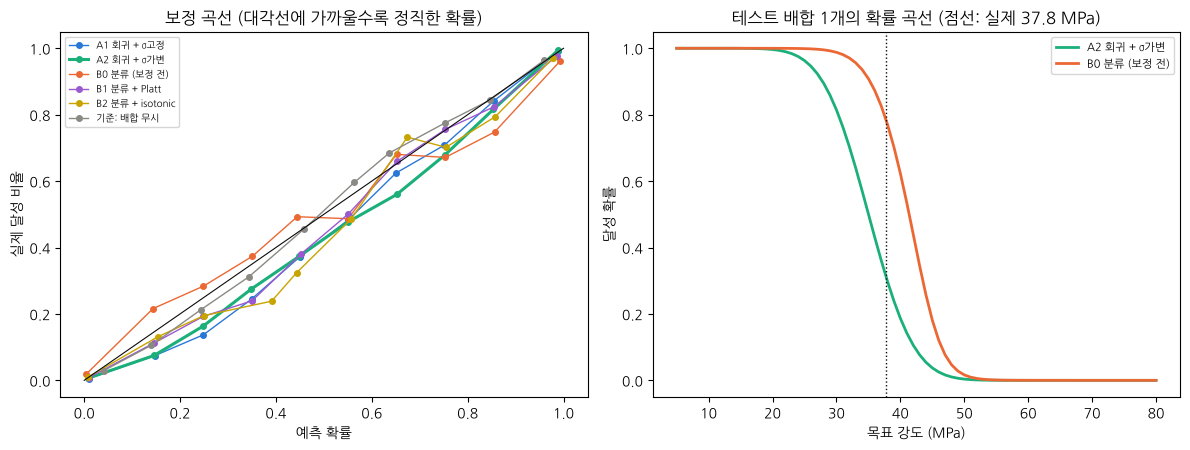

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
colors = {"A1 회귀 + σ고정": "#2a78d6", "A2 회귀 + σ가변": "#1baf7a", "B0 분류 (보정 전)": "#eb6834",
          "B1 분류 + Platt": "#9b59d0", "B2 분류 + isotonic": "#c8a400", "기준: 배합 무시": "#8a8984"}
for k, P in METHODS.items():
    fr, mp = calibration_curve(Y.ravel(), P.ravel(), n_bins=10)
    ax[0].plot(mp, fr, "o-", ms=4, color=colors[k], label=k, lw=2.2 if k == CHOSEN else 1)
ax[0].plot([0, 1], [0, 1], color="#0b0b0b", lw=0.8)
ax[0].set_xlabel("예측 확률"); ax[0].set_ylabel("실제 달성 비율"); ax[0].set_title("보정 곡선 (대각선에 가까울수록 정직한 확률)")
ax[0].legend(fontsize=7)
i = int(np.argsort(np.abs(mu_te - 35))[0])
for k in [CHOSEN, "B0 분류 (보정 전)"]:
    ax[1].plot(T_EVAL, METHODS[k][i], color=colors[k], lw=2, label=k)
ax[1].axvline(y_te[i], color="#0b0b0b", ls=":", lw=1)
ax[1].set_xlabel("목표 강도 (MPa)"); ax[1].set_ylabel("달성 확률")
ax[1].set_title(f"테스트 배합 1개의 확률 곡선 (점선: 실제 {y_te[i]:.1f} MPa)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 9. 활용 효과: 확률 기준으로 걸러서 시험하기

재령 28일 테스트 배합을 '시험 후보'로 보고, 선택된 방법의 달성 확률이 기준(50·80·90%) 이상인 배합만 시험한다고 가정합니다.

In [12]:
P_ch = METHODS[CHOSEN]
eff = []
for t in [24, 30, 40]:
    j = int(np.where(T_EVAL == t)[0][0])
    real = Y[m28, j].astype(bool); p = P_ch[m28, j]
    eff.append({"목표(MPa)": t, "기준": "전부 시험", "시험 수": int(m28.sum()), "합격률": real.mean(), "확보한 합격 배합": f"{real.sum()}/{real.sum()}", "시험 절감": 0.0})
    for th in [0.5, 0.8, 0.9]:
        sel = p >= th
        eff.append({"목표(MPa)": t, "기준": f"확률 ≥ {int(th * 100)}%", "시험 수": int(sel.sum()),
                    "합격률": real[sel].mean() if sel.any() else np.nan,
                    "확보한 합격 배합": f"{int((sel & real).sum())}/{int(real.sum())}", "시험 절감": 1 - sel.mean()})
display(pd.DataFrame(eff).set_index(["목표(MPa)", "기준"]).round(3))

시험 수    합격률 확보한 합격 배합  시험 절감
목표(MPa) 기준                                    
24      전부 시험      127  0.811   103/103  0.000
        확률 ≥ 50%   102  0.951    97/103  0.197
        확률 ≥ 80%    92  0.978    90/103  0.276
        확률 ≥ 90%    82  0.988    81/103  0.354
30      전부 시험      127  0.646     82/82  0.000
        확률 ≥ 50%    82  0.902     74/82  0.354
        확률 ≥ 80%    63  1.000     63/82  0.504
        확률 ≥ 90%    51  1.000     51/82  0.598
40      전부 시험      127  0.291     37/37  0.000
        확률 ≥ 50%    45  0.756     34/37  0.646
        확률 ≥ 80%    28  1.000     28/37  0.780
        확률 ≥ 90%    27  1.000     27/37  0.787

## 10. 예측 프로그램

- `predict(재료 7종, 목표강도, 재령=28)` → 달성 확률, 예상 강도 μ ± σ, 공식 예측 강도, W/B, 판정
- 선택: `fck`(설계기준강도)와 `s`(표준편차)를 넣으면 배합강도 f<sub>cr</sub>을 계산해 fck 기준·f<sub>cr</sub> 기준 확률을 함께 보여 줌
- f<sub>cr</sub> 산정식 (콘크리트 표준시방서 일반콘크리트의 배합강도 식으로 알려진 형태 — **원문으로 계수 확인 필요**):
  - fck ≤ 35 MPa: max(fck + 1.34s, (fck − 3.5) + 2.33s)
  - fck > 35 MPa: max(fck + 1.34s, 0.9fck + 2.33s)
  - s를 모를 때: fck < 21 → fck + 7, 21 ≤ fck ≤ 35 → fck + 8.5, fck > 35 → 1.1fck + 5.0
- 학습 범위 밖 재료량·재령은 경고. 목표 강도에는 제한이 없음

In [13]:
RANGES = df[MATERIALS + ["재령"]].agg(["min", "max"])


def required_strength(fck, s=None):
    if s is None:
        return fck + 7.0 if fck < 21 else (fck + 8.5 if fck <= 35 else 1.1 * fck + 5.0)
    return max(fck + 1.34 * s, (fck - 3.5) + 2.33 * s) if fck <= 35 else max(fck + 1.34 * s, 0.9 * fck + 2.33 * s)


def features_of(mix, age):
    d = pd.DataFrame([{**mix, "재령": float(age)}])
    return add_formula(d, A_FIT, B_FIT)


def prob_of(d, target):
    mu = float(REG.predict(d[F_REG])[0])
    if CHOSEN.startswith("A1"):
        return float(1 - norm.cdf((target - mu) / SIGMA)), mu, SIGMA
    if CHOSEN.startswith("A2"):
        s = float(sigma_var(np.array([mu]), d["재령계수"].values)[0])
        return float(1 - norm.cdf((target - mu) / s)), mu, s
    ts = np.unique(np.r_[T_TRAIN[T_TRAIN < target], target])          # 낮은 목표부터 누적 최솟값 → 단조 감소
    P = clf_raw(d, ts)[0]
    if CHOSEN.startswith("B1"):
        P = expit(PLATT[0] * logit(np.clip(P, 1e-6, 1 - 1e-6)) + PLATT[1])
    elif CHOSEN.startswith("B2"):
        P = iso.predict(P)
    return float(np.minimum.accumulate(P)[-1]), mu, SIGMA


def verdict(p):
    return ("시험해 볼 가치가 높음" if p >= 0.8 else "가능성 있음 — 배합 조정 검토" if p >= 0.5
            else "가능성 낮음 — 배합 수정 권장" if p >= 0.2 else "달성 어려움")


def predict(시멘트, 고로슬래그, 플라이애시, 물, 고성능감수제, 굵은골재, 잔골재, 목표강도, 재령=28, fck=None, s=None):
    mix = dict(시멘트=시멘트, 고로슬래그=고로슬래그, 플라이애시=플라이애시, 물=물, 고성능감수제=고성능감수제, 굵은골재=굵은골재, 잔골재=잔골재)
    warn = [f"{k} {v}: 학습 범위 {RANGES.loc['min', k]:g}~{RANGES.loc['max', k]:g} 밖"
            for k, v in {**mix, "재령": 재령}.items() if not RANGES.loc["min", k] <= v <= RANGES.loc["max", k]]
    d = features_of(mix, 재령)
    p, mu, sg = prob_of(d, 목표강도)
    out = {"목표 강도 달성 확률": f"{100 * p:.1f}%", "판정": verdict(p),
           "예상 강도 μ ± σ": f"{mu:.1f} ± {sg:.1f} MPa", "공식 예측 강도": f"{float(d['공식강도'].iloc[0]):.1f} MPa",
           "W/B": round(float(d["W/B"].iloc[0]), 3), "재령": 재령, "확률 계산 방법": CHOSEN}
    if fck is not None:
        fcr = required_strength(fck, s)
        out["fck 기준 확률"] = f"{100 * prob_of(d, fck)[0]:.1f}% (fck = {fck} MPa)"
        out["fcr 기준 확률"] = f"{100 * prob_of(d, fcr)[0]:.1f}% (fcr = {fcr:.1f} MPa)"
    out["경고"] = warn if warn else "없음"
    return out


examples = [
    dict(시멘트=350, 고로슬래그=0, 플라이애시=0, 물=180, 고성능감수제=0, 굵은골재=1000, 잔골재=780, 목표강도=24),
    dict(시멘트=350, 고로슬래그=0, 플라이애시=0, 물=180, 고성능감수제=0, 굵은골재=1000, 잔골재=780, 목표강도=35),
    dict(시멘트=250, 고로슬래그=100, 플라이애시=50, 물=170, 고성능감수제=8, 굵은골재=950, 잔골재=780, 목표강도=40, fck=30, s=3.5),
]
for e in examples:
    print(e, "\n →", predict(**e), "\n")

{'시멘트': 350, '고로슬래그': 0, '플라이애시': 0, '물': 180, '고성능감수제': 0, '굵은골재': 1000, '잔골재': 780, '목표강도': 24} 
 → {'목표 강도 달성 확률': '97.2%', '판정': '시험해 볼 가치가 높음', '예상 강도 μ ± σ': '34.5 ± 5.5 MPa', '공식 예측 강도': '34.1 MPa', 'W/B': 0.514, '재령': 28, '확률 계산 방법': 'A2 회귀 + σ가변', '경고': '없음'} 

{'시멘트': 350, '고로슬래그': 0, '플라이애시': 0, '물': 180, '고성능감수제': 0, '굵은골재': 1000, '잔골재': 780, '목표강도': 35} 
 → {'목표 강도 달성 확률': '46.5%', '판정': '가능성 낮음 — 배합 수정 권장', '예상 강도 μ ± σ': '34.5 ± 5.5 MPa', '공식 예측 강도': '34.1 MPa', 'W/B': 0.514, '재령': 28, '확률 계산 방법': 'A2 회귀 + σ가변', '경고': '없음'} 

{'시멘트': 250, '고로슬래그': 100, '플라이애시': 50, '물': 170, '고성능감수제': 8, '굵은골재': 950, '잔골재': 780, '목표강도': 40, 'fck': 30, 's': 3.5} 
 → {'목표 강도 달성 확률': '73.9%', '판정': '가능성 있음 — 배합 조정 검토', '예상 강도 μ ± σ': '44.7 ± 7.3 MPa', '공식 예측 강도': '42.6 MPa', 'W/B': 0.425, '재령': 28, '확률 계산 방법': 'A2 회귀 + σ가변', 'fck 기준 확률': '97.8% (fck = 30 MPa)', 'fcr 기준 확률': '91.5% (fcr = 34.7 MPa)', '경고': '없음'} 



In [14]:
# 직접 입력해서 예측하기
RUN_INTERACTIVE = False   # True 로 바꾸고 실행
if RUN_INTERACTIVE:
    vals = [float(input(f"{k} (kg/m³): ").replace(",", "")) for k in MATERIALS]
    t = float(input("목표 강도 (MPa): "))
    age = float(input("재령 (일, 기본 28): ") or 28)
    print(predict(*vals, 목표강도=t, 재령=age))

## 11. 모델 저장과 HTML 모델용 내보내기

- `concrete_target_model.joblib`: 파이썬에서 다시 쓸 모델
- `model_export.json`: HTML 모델이 읽는 가중치·스케일러·공식 계수·σ·보정 계수 (브라우저에서 같은 계산을 하도록)

In [15]:
def export_pipe(p, features):
    sc, m = p.named_steps["scale"], p.named_steps["mlp"]
    return {"features": features, "scale": sc.scale_.tolist(), "min": sc.min_.tolist(),
            "activation": m.activation, "out_activation": m.out_activation_,
            "coefs": [c.tolist() for c in m.coefs_], "intercepts": [b.tolist() for b in m.intercepts_]}


export = {
    "chosen": CHOSEN, "formula": {"A": float(A_FIT), "B": float(B_FIT)},
    "sigma": SIGMA, "sigma_var": {"coef": SIG_COEF, "min": SIG_MIN},
    "reg": export_pipe(REG, F_REG), "reg_name": best_name,
    "clf": export_pipe(CLF, F_CLF), "t_train": T_TRAIN.tolist(), "platt": PLATT,
    "iso": {"x": iso.X_thresholds_.tolist(), "y": iso.y_thresholds_.tolist()},
    "ranges": {**{k: [float(RANGES.loc["min", k]), float(RANGES.loc["max", k])] for k in RANGES.columns},
               "W/B": [float(add_formula(df, A_FIT, B_FIT)["W/B"].min()), float(add_formula(df, A_FIT, B_FIT)["W/B"].max())]},
    "metrics": {"strength": comp.reset_index().rename(columns={"index": "모델"}).to_dict("records"),
                "prob_all": prob_all.loc[[CHOSEN]].round(4).to_dict("records")[0],
                "prob_28": prob_28.loc[[CHOSEN]].round(4).to_dict("records")[0]},
    "data": {"rows": int(len(df)), "mixes": int(df["배합번호"].nunique()), "train": int(len(train)), "test": int(len(test))},
    "checks": [{"재료": e, "목표": t, "재령": 28, "확률": prob_of(features_of(e, 28), t)[0]}
               for e, t in [(examples[0] | {}, 24), (examples[2] | {}, 40)] for e in [{k: v for k, v in e.items() if k in MATERIALS}]],
}
with open("model_export.json", "w", encoding="utf-8") as f:
    json.dump(export, f, ensure_ascii=False)
joblib.dump({**{k: v for k, v in export.items() if k not in ("reg", "clf", "iso")}, "reg": REG, "clf": CLF, "iso": iso},
            "concrete_target_model.joblib")
print("저장: model_export.json, concrete_target_model.joblib | 선택 방법:", CHOSEN)
if IN_COLAB:
    colab_files.download("model_export.json")

저장: model_export.json, concrete_target_model.joblib | 선택 방법: A2 회귀 + σ가변
